# COMP 472 Project: Clustering (unsupervised learning)

Every team must run at least one clustering experiment. Its purpose is to look at the **structure of the feature representations**: do the examples form natural groups, and do those groups match the true labels?

The main clustering method is a **Gaussian Mixture Model (GMM)**, written from scratch with NumPy. The code was first written in `decision_tree_random_forest_sean/decision_tree_random_forest_gmm.ipynb` and moved here unchanged, except for three small plotting fixes marked in the code. Section 6 adds **k-means** on the image features, also written from scratch, as a second method to compare against.

**How it works.** A GMM assumes the data comes from k overlapping "blobs", each a Gaussian (bell-shaped) distribution with its own centre and spread. Here, each feature has its own spread within a blob (a *diagonal* Gaussian). Training repeats two steps (the EM algorithm) until the fit stops improving (at most 150 rounds):
- **E-step:** for every example, work out how likely it is to belong to each blob (its *responsibilities*).
- **M-step:** move each blob's centre and spread to fit the examples it is responsible for.

The labels are **never used for fitting**, only afterwards to check how well the clusters match them.

**Questions from the mandate**
- Do sentiment examples naturally separate into positive, neutral and negative groups? (Section 4)
- How does changing the number of clusters affect the results? (Sections 4 and 5)
- How closely do the clusters correspond to the true labels? (Sections 4 and 5)
- Do similar visual objects appear in similar clusters, and which classes are grouped together? (Sections 5 and 6)
- Does the data prefer as many clusters as there are labels? (Sections 4.2, 5.1 and 6.4)

**Data:** the full training files (12,000 sentiment and 20,000 image examples). No validation split is needed, because nothing is being trained to predict labels.

**Run time:** about 50 minutes on Colab's CPU (no GPU needed): about 20 for sentiment (Section 4), 30 for the image GMM (Section 5) and about 5 for image k-means and the silhouette check (Section 6). After Sections 1 to 3, Sections 4, 5 and 6 can each be run on their own.

## 1. Setup
Mount Drive, unzip the dataset, and load the two training files. The variable names are the ones the GMM code from `decision_tree_random_forest_sean/decision_tree_random_forest_gmm.ipynb` expects.

In [1]:
from google.colab import drive
drive.mount('/content/drive')

ZIP_PATH = '/content/drive/MyDrive/comp472/comp-472-project-fall-2026-concordia.zip'
DATA_DIR = '/content/data'

Mounted at /content/drive


In [2]:
import os, glob, zipfile, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

os.makedirs(DATA_DIR, exist_ok=True)
with zipfile.ZipFile(ZIP_PATH) as z:
    z.extractall(DATA_DIR)

def find_csv(name):
    """Find a CSV anywhere inside the extracted zip (handles nested folders)."""
    hits = [p for p in glob.glob(f'{DATA_DIR}/**/{name}', recursive=True) if '__MACOSX' not in p]
    if not hits:
        raise FileNotFoundError(f'{name} not found under {DATA_DIR}')
    return hits[0]

def load_train(task):
    df = pd.read_csv(find_csv(f'{task}_train.csv'))
    return df.drop(columns=['id', 'label']).to_numpy(), df['label'].to_numpy()

full_sentiment_train_X, full_sentiment_train_Y = load_train('sentiment')
full_image_train_X, full_image_train_Y = load_train('image')
print('sentiment:', full_sentiment_train_X.shape, '| image:', full_image_train_X.shape)

sentiment: (12000, 768) | image: (20000, 500)


## 2. The GMM functions
Copied unchanged from `decision_tree_random_forest_sean/decision_tree_random_forest_gmm.ipynb`.
- `init_gmm`: equal weights, k randomly chosen examples as the starting centres, and the overall spread of each feature as the starting spread
- `e_step`: each example's responsibilities, computed with logarithms to avoid numbers too small for the computer to store
- `m_step`: new weights, centres and spreads from the responsibilities (a tiny 1e-6 is added to each spread so it never reaches 0; on the image features, many spreads end up at this floor, which inflates the log-likelihood, see 6.4)
- `fit_gmm`: alternates the two steps until the log-likelihood (how well the model explains the data) improves by less than `tol`, or for at most 150 rounds. With `tol = 1e-4` and log-likelihoods in the millions, the fits most likely always run all 150 rounds

In [ ]:
def init_gmm(inputs, num_clusters):

    num_rows, _ = inputs.shape

    weights = np.full(num_clusters, 1/num_clusters)

    row_idx = np.random.choice(num_rows, num_clusters, replace=False)

    means = inputs[row_idx]
    variances = np.tile(inputs.var(axis=0), (num_clusters, 1))

    return weights, means, variances

def e_step(inputs, weights, means, variances):

    num_rows, _ = inputs.shape
    num_clusters = len(weights)

    log_joint = np.empty((num_rows, num_clusters))

    for num in range(num_clusters):
        log_density = -0.5 * np.sum(np.log(2 * np.pi * variances[num]) + (inputs - means[num]) ** 2 / variances[num], axis=1)
        log_joint[:, num] = np.log(weights[num]) + log_density

    row_max = log_joint.max(axis=1, keepdims=True)
    row_log_sum = row_max + np.log(np.sum(np.exp(log_joint - row_max), axis=1, keepdims=True))

    responsibilities = np.exp(log_joint - row_log_sum)

    return responsibilities, row_log_sum

def m_step(inputs, resp):
    num_rows = inputs.shape[0]
    effective_sizes = resp.sum(axis=0)

    weights = effective_sizes / num_rows

    means = (resp.T @ inputs) / effective_sizes[:, None]
    variances  = (resp.T @ (inputs ** 2)) / effective_sizes[:, None] - means ** 2 + 1e-6

    return weights, means, variances

def fit_gmm(inputs, num_clusters, max_iter, tol):
    weights, means, variances = init_gmm(inputs, num_clusters)

    previous_ll = -np.inf

    for iter in range(max_iter):
        responsibilities, row_log_sum = e_step(inputs, weights, means, variances)
        ll = log_likelihood(row_log_sum)


        if abs(ll - previous_ll) < tol:
            break

        weights, means, variances = m_step(inputs, responsibilities)
        previous_ll = ll

    return weights, means, variances

def log_likelihood(log_row_sum):

    total = np.sum(log_row_sum)
    return total

## 3. Measuring how well clusters match the labels
Two numbers, both from comparing each example's cluster with its true label:
- **Purity:** give each cluster its most common label and count how many examples that gets right. Easy to read, but it rises automatically with more clusters (with one cluster per example it would be 100%), so it only compares fairly at the same k. With random clusters it is a little above the share of the largest class: about 34% for sentiment with 3 clusters, and about 4% for image with 50 clusters (a random cluster of about 400 images happens to hold more of some classes than others). The printed lines in 4.3, 5.3 and 6.1 say 33% and 2%, which are slightly too low.
- **Adjusted Rand index (ARI):** how often pairs of examples are grouped the same way in the clusters and in the labels, corrected for chance. 0 means no better than random grouping, 1 means the clusters match the labels exactly. Computed with sklearn's metrics, which the coding rules allow.

In [3]:
from sklearn.metrics import adjusted_rand_score

def purity(clusters, labels):
    counts = pd.crosstab(clusters, labels)
    return counts.max(axis=1).sum() / len(labels)

def cluster_with_gmm(X, k, seed=42):
    """Fit a GMM with k clusters and give each example its most likely cluster."""
    np.random.seed(seed)
    weights, means, variances = fit_gmm(X, k, 150, 1e-4)
    resp, _ = e_step(X, weights, means, variances)
    return resp.argmax(axis=1)

## 4. Sentiment
### 4.1 First runs
From `decision_tree_random_forest_sean/decision_tree_random_forest_gmm.ipynb`, unchanged: a first fit on 1,000 examples, then on all 12,000, each with 3 clusters. The output is the fitted weights, centres and spreads.

In [ ]:
np.random.seed(42)

subset_size = 1000

indices = np.random.choice(len(full_sentiment_train_X), size=subset_size, replace=False)

train_sentiment_subset_X = full_sentiment_train_X[indices]

fit_gmm(train_sentiment_subset_X, num_clusters = 3, max_iter = 150, tol = 1e-4)

fit_gmm(full_sentiment_train_X, num_clusters = 3, max_iter = 150, tol = 1e-4)

(array([0.39298054, 0.12625606, 0.48076341]),
 array([[ 0.17993744, -0.07933858,  0.53719523, ..., -0.16474593,
          0.08926229, -0.03208969],
        [-0.13196208, -0.27501138,  0.23807511, ..., -0.05963091,
          0.08427714, -0.07051712],
        [ 0.15354093, -0.08214958,  0.3201401 , ..., -0.121894  ,
          0.15381165, -0.08778184]], shape=(3, 768)),
 array([[0.03161509, 0.03277372, 0.04764236, ..., 0.02910285, 0.02287816,
         0.03133172],
        [0.0512131 , 0.04101042, 0.06426966, ..., 0.04233628, 0.0322724 ,
         0.0369041 ],
        [0.04298691, 0.05050932, 0.06342505, ..., 0.03780372, 0.0324049 ,
         0.03522277]], shape=(3, 768)))

### 4.2 How many clusters does the data prefer?
From `decision_tree_random_forest_sean/decision_tree_random_forest_gmm.ipynb`, unchanged. **BIC** (Bayesian information criterion) scores a fit by how well it explains the data, minus a penalty for every extra parameter. The lowest BIC marks the number of clusters the data supports best. About 10 minutes.

**Reading the result:** BIC is lowest at 12 clusters, the second-largest number tried, but the 13-cluster fit has a *lower* log-likelihood than the 12-cluster one. A model with more clusters can always fit at least as well, so that fit got stuck (a poor random start, or the 150-round limit). The exact best number is therefore uncertain, but it is clearly well above 3: the strongest structure in the embeddings is something other than sentiment.


In [ ]:
np.random.seed(42)

def bic_for_k(inputs, k, max_iter=150, tol=1e-4):
    weights, means, variances = fit_gmm(inputs, k, max_iter, tol)
    _, row_log_sum = e_step(inputs, weights, means, variances)
    ll = log_likelihood(row_log_sum)
    n, d = inputs.shape
    p = (k - 1) + 2 * k * d
    bic = p * np.log(n) - 2 * ll
    return ll, bic

bic_results = {}
for k in range(2, 14):
    ll, bic = bic_for_k(full_sentiment_train_X, k)
    bic_results[k] = (ll, bic)
    print(f"k={k}  ll={ll:.2f}  BIC={bic:.2f}")

k=2  ll=2522834.90  BIC=-5016806.14
k=3  ll=2628009.34  BIC=-5212718.50
k=4  ll=2711326.98  BIC=-5364917.28
k=5  ll=2783298.50  BIC=-5494423.79
k=6  ll=2821314.47  BIC=-5556019.20
k=7  ll=2886486.09  BIC=-5671925.93
k=8  ll=2927888.64  BIC=-5740294.49
k=9  ll=2964641.05  BIC=-5799362.79
k=10  ll=3010733.31  BIC=-5877110.80
k=11  ll=3038730.58  BIC=-5918668.82
k=12  ll=3059929.46  BIC=-5946630.05
k=13  ll=3053520.95  BIC=-5919376.52


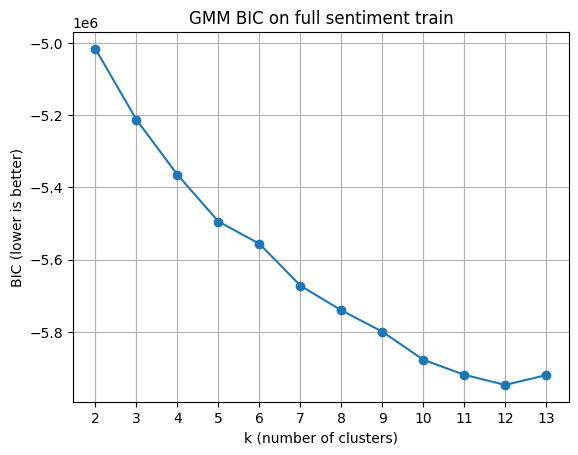

In [ ]:
import matplotlib.pyplot as plt

ks = sorted(bic_results)
bics = [bic_results[k][1] for k in ks]
plt.plot(ks, bics, marker="o")
plt.xlabel("k (number of clusters)")
plt.ylabel("BIC (lower is better)")
plt.title("GMM BIC on full sentiment train")
plt.xticks(ks)
plt.grid(True)
plt.show()

### 4.3 Do 3 clusters match Negative, Neutral and Positive?
If the BERT features grouped reviews by sentiment, 3 clusters should line up with the 3 labels. The table shows, for each cluster, how its reviews split across the true sentiments (each row adds to 100%).

In [ ]:
SENTIMENT_NAMES = ['Negative', 'Neutral', 'Positive']
clusters_3 = cluster_with_gmm(full_sentiment_train_X, 3)
table = pd.crosstab(clusters_3, full_sentiment_train_Y, normalize='index') * 100
table.columns = SENTIMENT_NAMES
table.index.name = 'cluster'
table['size'] = np.bincount(clusters_3)
print(table.round(1).to_string())
print(f'\npurity {purity(clusters_3, full_sentiment_train_Y):.1%} (random clusters: about 33%) | '
      f'ARI {adjusted_rand_score(full_sentiment_train_Y, clusters_3):.3f} (0 = random, 1 = perfect)')

         Negative  Neutral  Positive  size
cluster                                   
0            32.4     43.9      23.7  3349
1            39.0     27.3      33.6  4367
2            28.2     31.2      40.5  4284

purity 40.9% (random clusters: about 33%) | ARI 0.016 (0 = random, 1 = perfect)


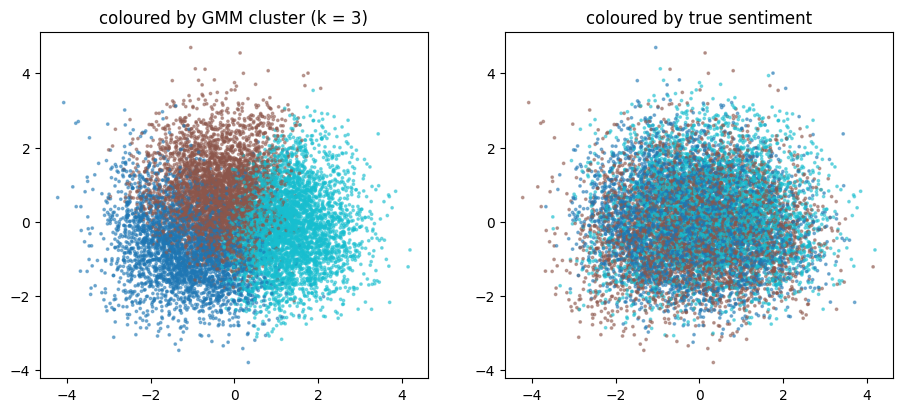

In [ ]:
X = full_sentiment_train_X - full_sentiment_train_X.mean(axis=0)
_, _, Vt = np.linalg.svd(X, full_matrices=False)
xy = X @ Vt[:2].T                                   # first two principal components
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
for ax, colour, title in [(axes[0], clusters_3, 'coloured by GMM cluster (k = 3)'),
                          (axes[1], full_sentiment_train_Y, 'coloured by true sentiment')]:
    ax.scatter(xy[:, 0], xy[:, 1], c=colour, cmap='tab10', s=3, alpha=0.5)
    ax.set_title(title)
plt.show()

### 4.4 Effect of the number of clusters
Purity and ARI for several values of k. Purity rises with k by construction, so ARI is the fairer measure across k. About 5 minutes.

In [ ]:
rows = []
for k in [2, 3, 4, 6, 8, 12]:
    clusters = cluster_with_gmm(full_sentiment_train_X, k)
    rows.append(dict(k=k, purity=round(purity(clusters, full_sentiment_train_Y), 3),
                     ARI=round(adjusted_rand_score(full_sentiment_train_Y, clusters), 3),
                     smallest_cluster=np.bincount(clusters).min(), largest_cluster=np.bincount(clusters).max()))
print(pd.DataFrame(rows).to_string(index=False))

 k  purity   ARI  smallest_cluster  largest_cluster
 2   0.378 0.010              5485             6515
 3   0.409 0.016              3349             4367
 4   0.402 0.016               311             4246
 6   0.411 0.017               306             3160
 8   0.439 0.025               290             2155
12   0.469 0.021               264             1452


### 4.5 Looking at 12 clusters
From `decision_tree_random_forest_sean/decision_tree_random_forest_gmm.ipynb`, with one fix: the scatter's colour map was `tab10`, which has only 10 colours, so 2 of the 12 clusters shared a colour. It is now `tab20`.
- **Scatter:** every review placed by its first two principal components (the two directions along which the features vary most), coloured by cluster.
- **Heatmap:** for each cluster, the share of its reviews with each true sentiment (each row adds to 1).

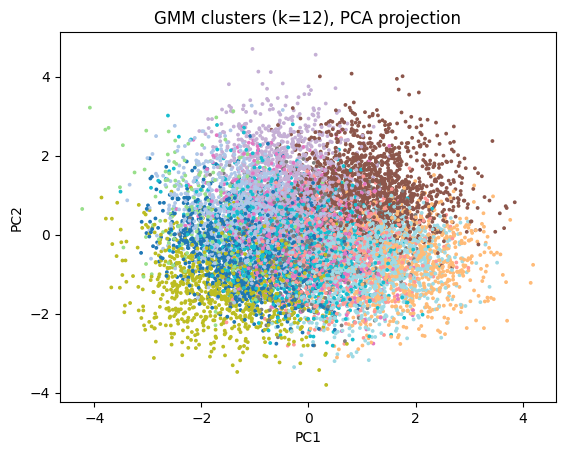

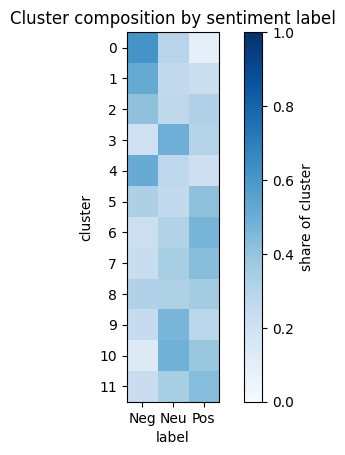

In [ ]:
import matplotlib.pyplot as plt
import pandas as pd

np.random.seed(42)
k_chosen = 12   # set this to the k you pick

weights, means, variances = fit_gmm(full_sentiment_train_X, k_chosen, 150, 1e-4)
resp, _ = e_step(full_sentiment_train_X, weights, means, variances)
clusters = resp.argmax(axis=1)

# 1. Scatter of clusters in 2D (PCA)
centered = full_sentiment_train_X - full_sentiment_train_X.mean(axis=0)
_, _, vt = np.linalg.svd(centered, full_matrices=False)
coords = centered @ vt[:2].T
plt.scatter(coords[:, 0], coords[:, 1], c=clusters, s=3, cmap="tab20")   # fixed: was "tab10", which has only 10 colours for 12 clusters
plt.xlabel("PC1"); plt.ylabel("PC2")
plt.title(f"GMM clusters (k={k_chosen}), PCA projection")
plt.show()

# 2. Cluster-by-label heatmap (row-normalized: share of each cluster per label)
ct = pd.crosstab(clusters, full_sentiment_train_Y)
share = ct.div(ct.sum(axis=1), axis=0)
plt.imshow(share.values, cmap="Blues", vmin=0, vmax=1)
plt.colorbar(label="share of cluster")
plt.xticks(range(3), ["Neg", "Neu", "Pos"])
plt.yticks(range(k_chosen), share.index)
plt.xlabel("label"); plt.ylabel("cluster")
plt.title("Cluster composition by sentiment label")
plt.show()

## 5. Image
### 5.1 How many clusters does the data prefer?
The BIC loop from `decision_tree_random_forest_sean/decision_tree_random_forest_gmm.ipynb`, unchanged. Its one cell is split here into three (BIC, plot, 12-cluster plots). About 16 minutes.

**Reading the result:** two fits are worse than the one before them (10 clusters vs 9, and 13 vs 12), so single random starts often get stuck on these features. Otherwise BIC keeps falling as clusters are added; 6.4 explains why BIC is not a good guide here.


In [ ]:
np.random.seed(42)

def bic_for_k(inputs, k, max_iter=150, tol=1e-4):
    weights, means, variances = fit_gmm(inputs, k, max_iter, tol)
    _, row_log_sum = e_step(inputs, weights, means, variances)
    ll = log_likelihood(row_log_sum)
    n, d = inputs.shape
    p = (k - 1) + 2 * k * d
    bic = p * np.log(n) - 2 * ll
    return ll, bic

bic_results = {}
for k in range(2, 14):
    ll, bic = bic_for_k(full_image_train_X, k)
    bic_results[k] = (ll, bic)
    print(f"k={k}  ll={ll:.2f}  BIC={bic:.2f}")

    import matplotlib.pyplot as plt

k=2  ll=19211648.25  BIC=-38403479.63
k=3  ll=19633307.02  BIC=-39236883.77
k=4  ll=19722545.02  BIC=-39405446.38
k=5  ll=20026687.04  BIC=-40003817.02
k=6  ll=20425945.04  BIC=-40792419.65
k=7  ll=20486938.92  BIC=-40904494.00
k=8  ll=20507356.20  BIC=-40935415.18
k=9  ll=20812325.14  BIC=-41535439.66
k=10  ll=20745343.12  BIC=-41391562.23
k=11  ll=20956515.60  BIC=-41803993.80
k=12  ll=21147483.21  BIC=-42176015.62
k=13  ll=20986328.17  BIC=-41843792.16


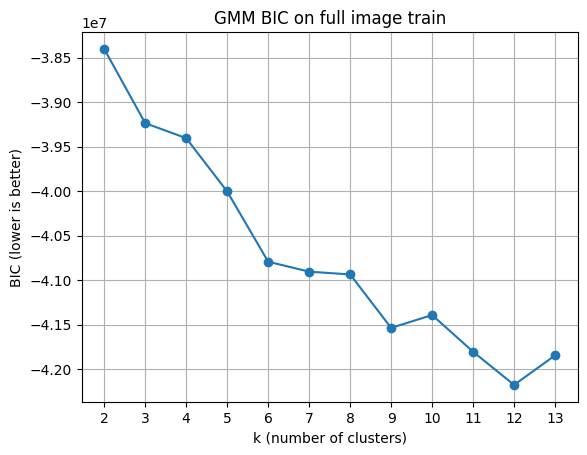

In [ ]:
ks = sorted(bic_results)
bics = [bic_results[k][1] for k in ks]
plt.plot(ks, bics, marker="o")
plt.xlabel("k (number of clusters)")
plt.ylabel("BIC (lower is better)")
plt.title("GMM BIC on full image train")
plt.xticks(ks)
plt.grid(True)
plt.show()

### 5.2 Looking at 12 clusters
From `decision_tree_random_forest_sean/decision_tree_random_forest_gmm.ipynb`, with three fixes, all marked in the code:
- the scatter's colour map was `"vmax"`, which is not a colour map, so the cell stopped with an error. It is now `tab20`.
- the heatmap's x-axis showed the three sentiment labels, but image has 50 classes. It now shows class numbers.
- the heatmap is wider so 50 class columns fit.

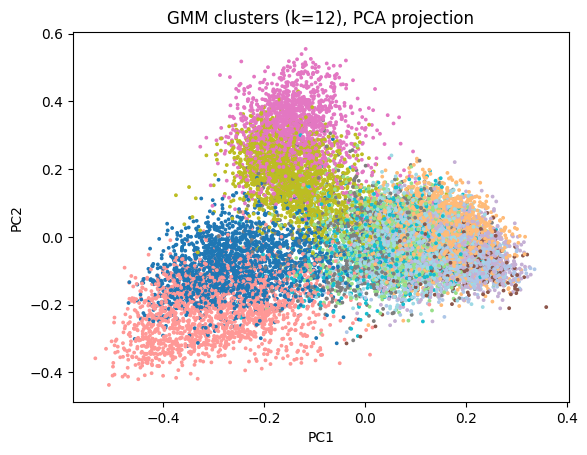

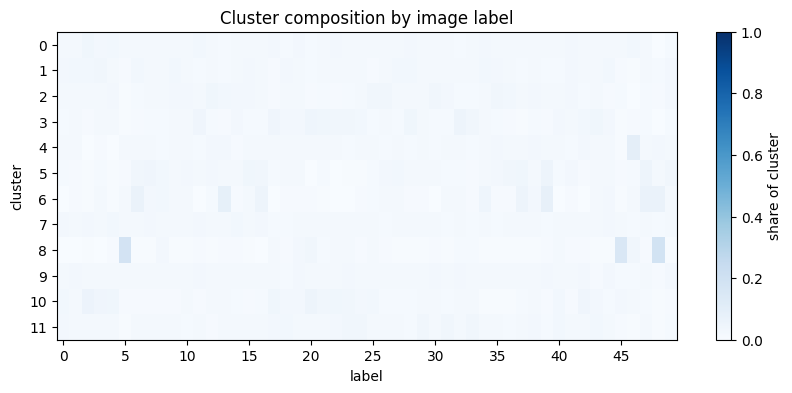

In [ ]:
import matplotlib.pyplot as plt
import pandas as pd

np.random.seed(42)
k_chosen = 12   # set this to the k you pick

weights, means, variances = fit_gmm(full_image_train_X, k_chosen, 150, 1e-4)
resp, _ = e_step(full_image_train_X, weights, means, variances)
clusters = resp.argmax(axis=1)

# 1. Scatter of clusters in 2D (PCA)
centered = full_image_train_X - full_image_train_X.mean(axis=0)
_, _, vt = np.linalg.svd(centered, full_matrices=False)
coords = centered @ vt[:2].T
plt.scatter(coords[:, 0], coords[:, 1], c=clusters, s=3, cmap="tab20")   # fixed: "vmax" is not a colormap, so this line raised an error
plt.xlabel("PC1"); plt.ylabel("PC2")
plt.title(f"GMM clusters (k={k_chosen}), PCA projection")
plt.show()

# 2. Cluster-by-label heatmap (row-normalized: share of each cluster per label)
ct = pd.crosstab(clusters, full_image_train_Y)
share = ct.div(ct.sum(axis=1), axis=0)
plt.figure(figsize=(10, 4))   # added: wide enough for 50 class columns
plt.imshow(share.values, cmap="Blues", vmin=0, vmax=1, aspect="auto")
plt.colorbar(label="share of cluster")
plt.xticks(range(0, 50, 5))   # fixed: was the 3 sentiment labels, but image has 50 classes
plt.yticks(range(k_chosen), share.index)
plt.xlabel("label"); plt.ylabel("cluster")
plt.title("Cluster composition by image label")
plt.show()

### 5.3 Do 50 clusters match the 50 classes?
One cluster per class. If each object formed its own blob in feature space, purity and ARI would be high. About 10 minutes.

In [ ]:
clusters_50 = cluster_with_gmm(full_image_train_X, 50)
sizes = np.bincount(clusters_50, minlength=50)
print(f'purity {purity(clusters_50, full_image_train_Y):.1%} (random clusters: about 2%) | '
      f'ARI {adjusted_rand_score(full_image_train_Y, clusters_50):.3f} (0 = random, 1 = perfect)')
print(f'cluster sizes: smallest {sizes.min()}, largest {sizes.max()} (each class has 400 images)')

purity 8.1% (random clusters: about 2%) | ARI 0.013 (0 = random, 1 = perfect)
cluster sizes: smallest 2, largest 1314 (each class has 400 images)


### 5.4 Which classes are grouped together?
For each class, the share of its 400 images in each of the 50 clusters. Two classes are *grouped together* when their images fall into the same clusters. The overlap score is the sum, over all clusters, of the smaller of the two classes' shares: 0 if they never share a cluster, 1 if they spread over the clusters in exactly the same way. Because every cluster mixes many classes, most pairs overlap a fair amount, so the typical (median) overlap is printed for comparison.

The class numbers have no names in the dataset. The comparison notebook found that models confuse classes with nearby numbers (within 2) about twice as often as chance. The last line checks whether the clusters show the same pattern.

In [ ]:
share = pd.crosstab(full_image_train_Y, clusters_50, normalize='index').to_numpy()   # rows: classes
pairs = []
for a in range(50):
    for b in range(a + 1, 50):
        pairs.append(dict(a=a, b=b, overlap=np.minimum(share[a], share[b]).sum()))
pairs = pd.DataFrame(pairs).sort_values('overlap', ascending=False)
print(f"overlap of a typical pair (median of all 1,225 pairs): {pairs['overlap'].median():.3f}")
print('class pairs that share clusters the most:')
print(pairs.head(10).round(3).to_string(index=False))

top = pairs.head(20)
near = np.mean(np.abs(top['a'] - top['b']) <= 2)
chance = np.mean(np.abs(pairs['a'] - pairs['b']) <= 2)
print(f'\nof the 20 most-grouped pairs, {near:.0%} have numbers within 2 of each other (all pairs: {chance:.1%})')

overlap of a typical pair (median of all 1,225 pairs): 0.642
class pairs that share clusters the most:
 a  b  overlap
26 36    0.815
21 22    0.815
14 38    0.815
33 40    0.805
30 31    0.805
 9 26    0.803
24 40    0.800
22 23    0.798
 7 34    0.795
 6  7    0.793

of the 20 most-grouped pairs, 35% have numbers within 2 of each other (all pairs: 7.9%)


## 6. Image: k-means
The GMM fits the image features poorly: they are 85% zeros, and a Gaussian blob is a poor shape for that kind of data. Its 50 clusters ranged from 2 images to over 1,000. **k-means** is a simpler method the mandate also lists. It only uses distances, like k-NN, which works well on these features (56% with one neighbour).

**How it works.** Pick k examples at random as starting centres, then repeat until the centres stop moving:
1. assign every example to its nearest centre
2. move each centre to the average of the examples assigned to it

Unlike the GMM, each example belongs to exactly one cluster, and every cluster has the same round shape. Written from scratch with NumPy.

In [5]:
def kmeans(X, k, n_iter=100, seed=42):
    """k-means clustering. Returns each example's cluster and the number of rounds it took."""
    rng = np.random.default_rng(seed)
    centers = X[rng.choice(len(X), k, replace=False)]           # k random examples as the starting centres
    for round_ in range(1, n_iter + 1):
        # squared distance from every example to every centre: |x|^2 - 2 x.c + |c|^2
        dist = (X ** 2).sum(axis=1)[:, None] - 2 * X @ centers.T + (centers ** 2).sum(axis=1)[None, :]
        clusters = dist.argmin(axis=1)                          # step 1: nearest centre
        new_centers = np.array([X[clusters == j].mean(axis=0) if np.any(clusters == j) else centers[j]
                                for j in range(k)])             # step 2: average of each cluster
        if np.allclose(new_centers, centers):                   # centres stopped moving
            break
        centers = new_centers
    return clusters, round_

def sqrt_scaling(X):
    """Square root of every value, then each row rescaled to length 1: the scaling that worked best for k-NN."""
    A = np.sqrt(X)
    return A / np.linalg.norm(A, axis=1, keepdims=True)

### 6.1 Do 50 clusters match the 50 classes?
k-means with 50 clusters on the raw features and on square-root-scaled features (the scaling that worked best for k-NN). If Section 5.3 has been run, the GMM's result is shown on the first line for comparison.

In [6]:
rows = []
if 'clusters_50' in globals():
    rows.append(dict(method='GMM (Section 5.3)', scaling='raw',
                     purity=purity(clusters_50, full_image_train_Y),
                     ARI=adjusted_rand_score(full_image_train_Y, clusters_50),
                     smallest=np.bincount(clusters_50, minlength=50).min(), largest=np.bincount(clusters_50).max(),
                     seconds=np.nan))
image_inputs = {'raw': full_image_train_X, 'sqrt': sqrt_scaling(full_image_train_X)}
kmeans_50 = {}
for scaling, X in image_inputs.items():
    start = time.time()
    clusters, rounds = kmeans(X, 50)
    kmeans_50[scaling] = clusters
    sizes = np.bincount(clusters, minlength=50)
    rows.append(dict(method=f'k-means ({rounds} rounds)', scaling=scaling,
                     purity=purity(clusters, full_image_train_Y),
                     ARI=adjusted_rand_score(full_image_train_Y, clusters),
                     smallest=sizes.min(), largest=sizes.max(), seconds=time.time() - start))
table = pd.DataFrame(rows)
table['purity'] = (table['purity'] * 100).round(1)
print('50 clusters vs the 50 classes (purity in %, random clusters: about 2%; each class has 400 images)')
print(table.round({'ARI': 3, 'seconds': 0}).to_string(index=False, na_rep='-'))

50 clusters vs the 50 classes (purity in %, random clusters: about 2%; each class has 400 images)
             method scaling  purity   ARI  smallest  largest  seconds
k-means (71 rounds)     raw    10.0 0.022       105      873     25.0
k-means (68 rounds)    sqrt    10.6 0.023       104      904     18.0


### 6.2 Effect of the number of clusters
k-means on the square-root-scaled features with 10 to 100 clusters. As before, purity rises with k by construction, so ARI is the fairer measure across k. `rounds` is how many rounds k-means took: 100 means it stopped at the limit before the centres had fully settled, so that result may not have fully settled.

In [ ]:
rows = []
for k in [10, 25, 50, 100]:
    clusters, rounds = kmeans(image_inputs['sqrt'], k)
    rows.append(dict(k=k, purity=round(purity(clusters, full_image_train_Y) * 100, 1),
                     ARI=round(adjusted_rand_score(full_image_train_Y, clusters), 3), rounds=rounds))
print(pd.DataFrame(rows).to_string(index=False))

  k  purity   ARI  rounds
 10     4.9 0.006      61
 25     8.4 0.016     100
 50    10.6 0.023      68
100    14.1 0.029      46


### 6.3 Which classes are grouped together?
The same overlap score as 5.4, for k-means with 50 clusters on square-root-scaled features.

In [ ]:
share = pd.crosstab(full_image_train_Y, kmeans_50['sqrt'], normalize='index').to_numpy()   # rows: classes
pairs = pd.DataFrame([dict(a=a, b=b, overlap=np.minimum(share[a], share[b]).sum())
                      for a in range(50) for b in range(a + 1, 50)]).sort_values('overlap', ascending=False)
print(f"overlap of a typical pair (median of all 1,225 pairs): {pairs['overlap'].median():.3f}")
print('class pairs that share clusters the most:')
print(pairs.head(10).round(3).to_string(index=False))

top = pairs.head(20)
near = np.mean(np.abs(top['a'] - top['b']) <= 2)
chance = np.mean(np.abs(pairs['a'] - pairs['b']) <= 2)
print(f'\nof the 20 most-grouped pairs, {near:.0%} have numbers within 2 of each other (all pairs: {chance:.1%})')

overlap of a typical pair (median of all 1,225 pairs): 0.550
class pairs that share clusters the most:
 a  b  overlap
30 31    0.772
27 29    0.765
35 36    0.760
18 43    0.750
22 29    0.745
 2  4    0.740
 7 27    0.730
15 29    0.728
37 39    0.727
24 30    0.727

of the 20 most-grouped pairs, 40% have numbers within 2 of each other (all pairs: 7.9%)


### 6.4 Does the image data prefer 50 clusters?
BIC is not a good guide here. The features are 85% zeros, so within a cluster many features are exactly 0 for every image. Their spread then drops to the 1e-6 floor (Section 2), and each such feature adds about +6 to an image's log-likelihood. Extra clusters keep raising the fit this way, so BIC would likely keep improving past 50 whatever the true structure. This is most likely also why the image log-likelihoods are so large and why some GMM clusters hold only 2 images.

Instead, the **silhouette score** measures how well separated a clustering is. For each image it compares the average distance to its own cluster with the average distance to the nearest other cluster: +1 = tight, well-separated clusters, 0 = clusters that touch and overlap, negative = images closer, on average, to the nearest other cluster than to their own. It is computed with sklearn's metrics (allowed) on a fixed sample of 5,000 images to keep it fast.

The last line scores the **true 50 classes** as if they were clusters: how well the classes themselves separate.

In [7]:
from sklearn.metrics import silhouette_score

def silhouette(clusters):
    return silhouette_score(image_inputs['sqrt'], clusters, sample_size=5000, random_state=0)

rows = []
for k in [2, 3, 5, 8, 12, 20, 30, 50, 75, 100]:
    clusters, _ = kmeans(image_inputs['sqrt'], k)
    rows.append(dict(k=k, silhouette=round(silhouette(clusters), 4)))
print(pd.DataFrame(rows).to_string(index=False))
print(f'\ntrue 50 classes as clusters: silhouette {silhouette(full_image_train_Y):.4f}')

  k  silhouette
  2      0.0255
  3      0.0152
  5      0.0135
  8      0.0196
 12      0.0141
 20      0.0111
 30      0.0156
 50      0.0074
 75      0.0043
100      0.0045

true 50 classes as clusters: silhouette -0.0120
